# Fake job postings: EDA and preprocessing (notebook 01)

We get to know the EMSCAD dataset before touching any model: class balance, missing
data, duplicates, text lengths and simple spam-style flags. Every section feeds a
decision: what to drop, how to split, and which metrics to trust. The second half builds
the preprocessing that notebooks 02 (classical ML) and 03 (deep learning) share:
cleaning, engineered features, the model matrix, and the five saved train/val/test splits.

Run time: about 1 minute.

In [1]:
import sys, os; os.chdir(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else None; sys.path.insert(0, "."); import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from modules import data_helper as dh
from modules import features as ft
from modules.classical_runs import get_splits

DATA = "../data/fake_job_postings.csv"

In [2]:
SEEDS = [0, 1, 2, 3, 4]  # one split per seed; every model is evaluated on all five
SEED = 0

dh.seed_everything(SEED)  # Session 5: fix every seed so runs are reproducible
sns.set_theme(style="whitegrid")

## Load and audit the raw data

Load the CSV and run the audit from `modules/data_helper.py`: shape, class counts,
duplicate structure and label conflicts, before we change anything.

In [3]:
df = dh.load_raw(DATA)
a = dh.audit(df)
pd.Series({k: v for k, v in a.items() if k != "missing_rate"}, name="audit").to_frame()

,audit
shape,"[17880, 18]"
class_counts,"{0: 17014, 1: 866}"
positive_rate,0.048434
n_duplicate_rows,281
n_rows_shared_description,4552
n_conflicting_duplicate_groups,0


## Class balance

The target is heavily imbalanced, which drives every later choice of metric and
threshold (Sessions 6/7).

{0: 17014, 1: 866}


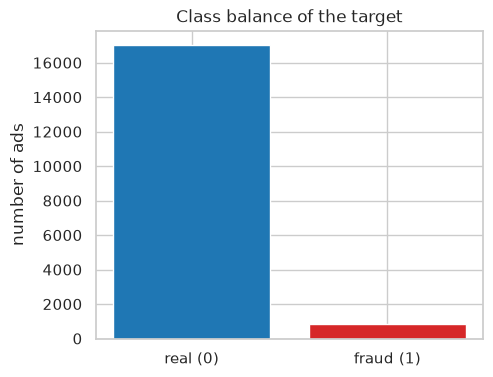

In [4]:
# Count ads per class.
counts = df["fraudulent"].value_counts().sort_index()
print(counts.to_dict())

# Bar chart of the two counts.
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["real (0)", "fraud (1)"], counts.values, color=["tab:blue", "tab:red"])
ax.set_title("Class balance of the target")
ax.set_ylabel("number of ads")
plt.show()

Reading: bar heights are numbers of ads on one shared linear scale; the imbalance
seen here is why accuracy is useless and why PR-AUC plus a validation threshold are
our headline tools.

## Missing values by class

Share of ads missing each column, real versus fraud. A gap between the two bars of
a pair means missingness itself is informative.

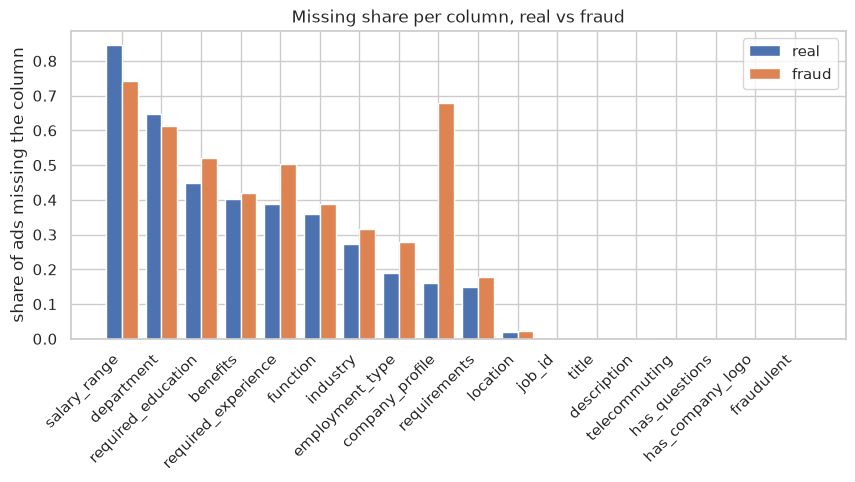

In [5]:
# Share of missing values per column, one column per class, sorted by the real-ad share.
by_class = pd.DataFrame({
    "real": df.loc[df["fraudulent"] == 0].isna().mean(),
    "fraud": df.loc[df["fraudulent"] == 1].isna().mean(),
}).sort_values("real", ascending=False)

# Side-by-side bars: real on the left of each pair, fraud on the right.
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(by_class))
ax.bar(x - 0.2, by_class["real"], 0.4, label="real")
ax.bar(x + 0.2, by_class["fraud"], 0.4, label="fraud")
ax.set_xticks(x, labels=by_class.index, rotation=45, ha="right")
ax.set_ylabel("share of ads missing the column")
ax.set_title("Missing share per column, real vs fraud")
ax.legend()
plt.show()

Reading: in each pair the left bar is real ads and the right bar fraudulent ads;
both use the same 0 to 1 scale.

## Duplicates and shared descriptions

The same posting can appear several times (exact duplicates), and different job_ids
can carry the same description text. If copies end up on both sides of a split,
evaluation leaks.

exact duplicate rows (ignoring job_id): 281
rows sharing their description with another row: 4552
duplicate blocks with conflicting labels: 0


largest description group: 380 ads


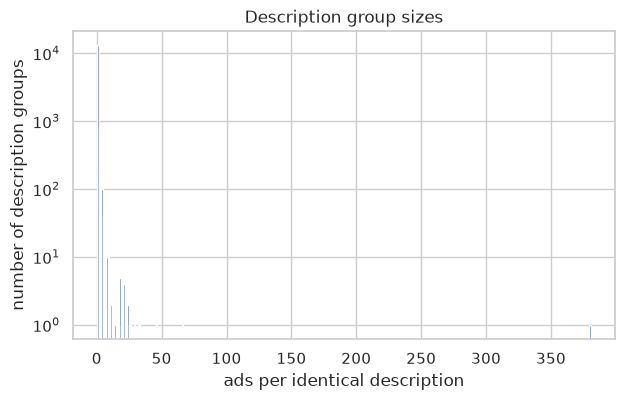

In [6]:
# Duplicate statistics from the audit.
print("exact duplicate rows (ignoring job_id):", a["n_duplicate_rows"])
print("rows sharing their description with another row:", a["n_rows_shared_description"])
print("duplicate blocks with conflicting labels:", a["n_conflicting_duplicate_groups"])

# Group ads by identical (normalised) description: lowercase, collapse whitespace.
desc = (df["description"].fillna("").astype(str).str.lower()
        .str.replace(r"\s+", " ", regex=True).str.strip())
sizes = desc.value_counts()
print("largest description group:", int(sizes.max()), "ads")

# Histogram of group sizes on a log y axis.
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(sizes.values, bins=np.arange(0.5, sizes.max() + 1.5, 1))
ax.set_yscale("log")
ax.set_xlabel("ads per identical description")
ax.set_ylabel("number of description groups")
ax.set_title("Description group sizes")
plt.show()

Reading: the y axis is log-scaled, so each gridline up is a tenfold jump in the
number of groups; bars on the right are descriptions repeated many times.

## Description length by class

Long versus short ads. The x axis is log-scaled because lengths span several orders
of magnitude.

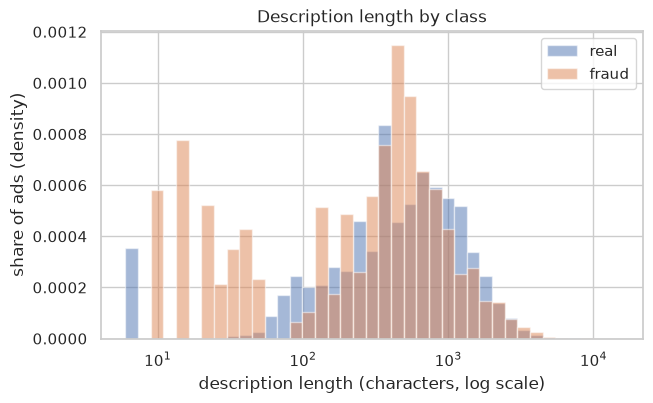

In [7]:
# Description lengths (non-empty only) and log-spaced bins to match the log x axis.
lens = df["description"].fillna("").str.len()
lens = lens[lens > 0]
bins = np.logspace(np.log10(lens.min()), np.log10(lens.max()), 40)

# Overlaid density histograms, one per class.
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(lens[df["fraudulent"] == 0], bins=bins, alpha=0.5, density=True, label="real")
ax.hist(lens[df["fraudulent"] == 1], bins=bins, alpha=0.5, density=True, label="fraud")
ax.set_xscale("log")
ax.set_xlabel("description length (characters, log scale)")
ax.set_ylabel("share of ads (density)")
ax.set_title("Description length by class")
ax.legend()
plt.show()

Reading: both histograms are densities, so the two classes are directly comparable
despite their very different sizes.

## Engineered flags by class

`modules/features.py` adds row-wise flags: missingness indicators, length and
capitalisation cues, and spam cues. Note that the dataset itself already replaced
real URLs, emails and phone numbers with placeholders such as `#URL_ab12cd#`, so the
flags look for those placeholders (plus a few plain-text patterns).

In [8]:
# Engineer the features, then the share of ads firing each binary flag, per class.
feats = ft.add_engineered_features(df)
flags = pd.DataFrame({
    "real": feats.loc[feats["fraudulent"] == 0, ft.BINARY_COLS].mean(),
    "fraud": feats.loc[feats["fraudulent"] == 1, ft.BINARY_COLS].mean(),
}).sort_values("fraud", ascending=False)
flags.round(3)

,real,fraud
missing_company_profile,0.160,0.678
missing_department,0.647,0.613
missing_benefits,0.402,0.420
has_money_words,0.205,0.398
has_company_logo,0.819,0.327
has_url,0.315,0.308
has_questions,0.502,0.289
has_salary,0.155,0.258
has_email,0.068,0.201
missing_requirements,0.149,0.178


Reading: each number is the share of ads in that class where the flag fires; 1.0
means every ad of that class fires it.

## Fraud rate by country

Only values seen on at least 100 ads, so the rates are not driven by a handful of
rows.

In [9]:
def fraud_rate(col, y, min_n=100):
    """Fraud rate per value of a column, keeping values with at least min_n ads."""
    t = pd.DataFrame({"value": col, "fraud": y}).groupby("value")["fraud"]
    t = t.agg(n="count", fraud_rate="mean")
    return t[t["n"] >= min_n].sort_values("fraud_rate", ascending=False)


fraud_rate(feats["country"], feats["fraudulent"])

,n,fraud_rate
value,,
AU,214,0.186916
US,10656,0.068506
missing,346,0.054913
CA,457,0.026258
IN,276,0.014493
GB,2384,0.009648
PH,132,0.007576
DE,383,0.000000
BE,117,0.000000


## Fraud rate by employment type

Same table for employment type, with missing as its own value.

In [10]:
fraud_rate(feats["employment_type"].fillna("missing"), feats["fraudulent"])

,n,fraud_rate
value,,
Part-time,797,0.092848
missing,3471,0.069432
Other,227,0.066079
Full-time,11620,0.042169
Contract,1524,0.028871
Temporary,241,0.008299


## Cleaning

Session 5: clean first, then split, then fit. `clean` drops exact duplicates (ignoring
`job_id`) and hashes each normalised description into a `group` id, so near-copies can
be kept on one side of every split later.

In [11]:
dfc = dh.clean(df)
print("rows before cleaning:", len(df), "| after:", len(dfc))
print("description groups:", dfc["group"].nunique())

rows before cleaning: 17880 | after: 17599
description groups: 14592


## Feature engineering

`add_engineered_features` adds the joined `text` column (title, company profile,
description, requirements, benefits), missing-value flags, length and capitalisation
statistics, and spam cues. These are computed row by row from the ad itself, so they
cannot leak information between splits.

In [12]:
dfe = ft.add_engineered_features(dfc)
new_cols = [c for c in dfe.columns if c not in df.columns]
print(len(new_cols), "new columns:", ", ".join(new_cols))
dfe[["title", "text"] + ft.NUMERIC_COLS[:3]].head(3)

16 new columns: group, text, country, has_salary, missing_company_profile, missing_requirements, missing_benefits, missing_department, desc_len, title_len, n_exclaim, n_upper_ratio, has_url, has_email, has_phone, has_money_words


,title,text,desc_len,title_len,n_exclaim
0,Marketing Intern,"Marketing Intern We're Food52, and we've creat...",905,16,1
1,Customer Service - Cloud Video Production,Customer Service - Cloud Video Production 90 S...,2077,41,5
2,Commissioning Machinery Assistant (CMA),Commissioning Machinery Assistant (CMA) Valor ...,355,39,0


## Splits: by description group, saved for all seeds

`make_splits` uses `StratifiedGroupKFold` on the group id (60/20/20, class ratio kept), so one
description can never sit in two splits. Each seed's indices are saved to `splits/` with a
fingerprint of the cleaned data; every notebook and every machine reloads exactly these rows.

In [13]:
y = dfe["fraudulent"].to_numpy()

# One row per (seed, split): size and fraud count.
rows = []
for seed in SEEDS:
    splits = get_splits(dfe, seed)  # loads splits/seed<N>.npz, creating it the first time
    for name, idx in splits.items():
        rows.append({"seed": seed, "split": name, "rows": len(idx),
                     "fraud": int(y[idx].sum()), "fraud rate": round(float(y[idx].mean()), 4)})

# Pivot to one line per seed.
pd.DataFrame(rows).pivot(index="seed", columns="split", values=["rows", "fraud"])

rows              fraud           
split  test  train   val  test train  val
seed                                     
0      3520  10559  3520   171   514  171
1      3520  10559  3520   171   514  171
2      3520  10559  3520   171   514  171
3      3520  10559  3520   171   514  171
4      3520  10559  3520   171   514  171

In [14]:
for seed in SEEDS:
    splits = get_splits(dfe, seed)

    # Description groups present in each split.
    groups = {name: set(dfe["group"].iloc[idx]) for name, idx in splits.items()}

    # No group may appear in two splits (otherwise copies of an ad leak across the split).
    for a_name, b_name in (("train", "val"), ("train", "test"), ("val", "test")):
        shared = groups[a_name] & groups[b_name]
        assert not shared, f"seed {seed}: {len(shared)} groups shared by {a_name} and {b_name}"
print("checked: no description group appears in two splits, for every seed")

checked: no description group appears in two splits, for every seed


## The model matrix (fitted on the training rows only)

`make_preprocessor` is one `ColumnTransformer`: TF-IDF over the joined text, one-hot
metadata, ordinal levels, scaled numeric statistics and the binary flags. Session 5: it
is fitted on the training rows only and then applied to validation and test.

In [15]:
split0 = get_splits(dfe, SEED)

# Fit on the training rows only, then transform validation with the fitted vocabulary and scales.
pre = ft.make_preprocessor("tfidf")
X_train = pre.fit_transform(dfe.iloc[split0["train"]])
X_val = pre.transform(dfe.iloc[split0["val"]])
names = pre.get_feature_names_out()
print("train matrix:", X_train.shape, "| validation matrix:", X_val.shape)

# Columns contributed by each block of the ColumnTransformer.
pd.Series([n.split("__")[0] for n in names]).value_counts().rename("columns per block").to_frame()

train matrix: (10559, 20128) | validation matrix: (3520, 20128)


,columns per block
text,20000
nominal,110
binary,12
numeric,4
ordinal,2


The binary-flag block passes through a `VarianceThreshold`: flags that are (almost)
always 0 or always 1 on the training rows carry no information and are dropped.

In [16]:
kept = {n.split("__", 1)[1] for n in names if n.startswith("binary__")}
dropped = [c for c in ft.BINARY_COLS if c not in kept]
print("flags kept   :", sorted(kept))
print("flags dropped:", dropped or "none")

flags kept   : ['has_company_logo', 'has_email', 'has_money_words', 'has_phone', 'has_questions', 'has_salary', 'has_url', 'missing_benefits', 'missing_company_profile', 'missing_department', 'missing_requirements', 'telecommuting']
flags dropped: none


## What the EDA tells us to do

- Drop exact duplicates before splitting: a copy of the same ad on both sides of a
  split would leak evaluation rows.
- Split by description group, not by row: near-identical ads must stay on one side
  of the split.
- The classes are heavily imbalanced: use PR-AUC as the headline metric, pick the
  decision threshold on validation, and never judge a model by accuracy alone.
- Missingness is informative: keep the missing-indicator flags instead of imputing
  them away.
- The text fields carry the strongest signal: keep the joined text central to the
  feature set and read model errors from it.
- Fit every transformer on the training rows only; the saved splits make that the same
  for every model, notebook and machine.